In [ ]:
!pip install scipy tqdm

🚀 Starting dataset generation: 500 samples...


100%|██████████| 500/500 [00:01<00:00, 414.13it/s]



✅ Dataset successfully generated and zipped to: charged_bumblebee_ml_dataset.zip


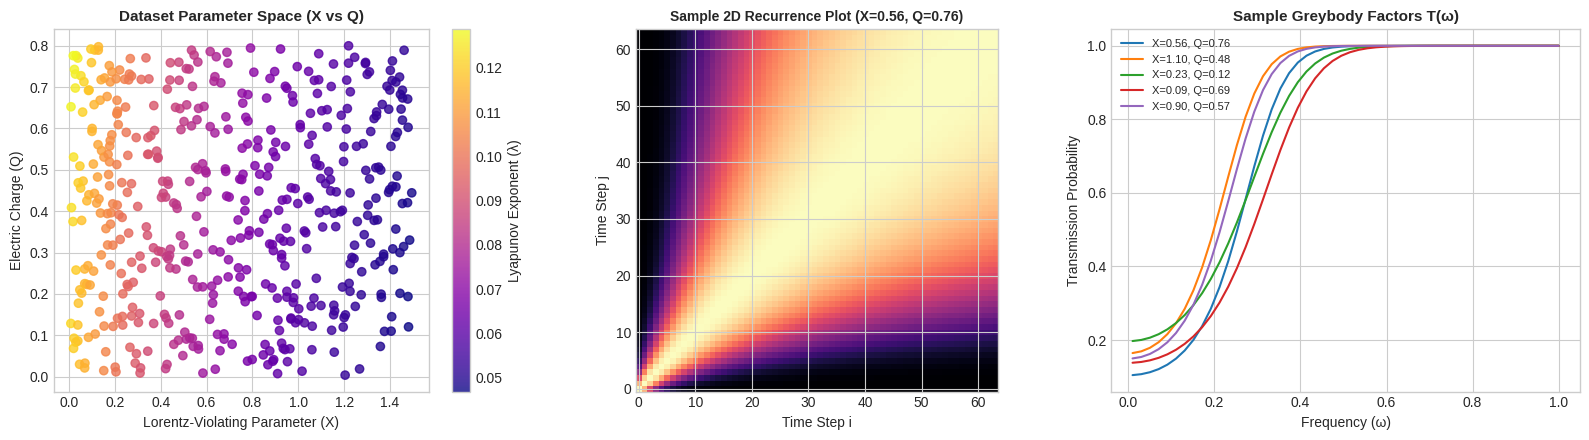


📥 Run the following snippet in your next Colab cell to download the zipped dataset:
from google.colab import files
files.download('charged_bumblebee_ml_dataset.zip')


In [ ]:

# ==============================================================================
# CHARGED BUMBLEBEE BLACK HOLE DATASET GENERATOR FOR ML / DEEP LEARNING
# Generates: Metadata CSV, 2D Recurrence Plot Images (.npz), and Greybody Curves
# ==============================================================================

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.optimize import minimize_scalar
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 1. PARAMETERS &amp; CONFIGURATION
# ------------------------------------------------------------------------------
NUM_SAMPLES = 500       # Total dataset samples to generate
GRID_SIZE = 64          # Resolution for 2D Recurrence Plots (64x64)
M = 1.0                 # Black hole mass (M=1)
SEED = 42

np.random.seed(SEED)
OUTPUT_DIR = "./bumblebee_dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"🚀 Starting dataset generation: {NUM_SAMPLES} samples...")

# ------------------------------------------------------------------------------
# 2. HELPER PHYSICS FUNCTIONS
# ------------------------------------------------------------------------------
def metric_function(r, X, Q, M=1.0):
    """Bumblebee metric potential f(r)."""
    return (1.0 / (1.0 + X)) - (2.0 * M / ((1.0 + X) * r)) + (2.0 * Q**2 / ((2.0 + X) * r**2))

def outer_horizon(X, Q, M=1.0):
    """Computes event horizon radius r_+."""
    disc = 1.0 - (2.0 * (1.0 + X) * Q**2) / ((2.0 + X) * M**2)
    if disc < 0:
        return None  # Naked singularity
    return M * (1.0 + np.sqrt(disc))

def photon_sphere(X, Q, M=1.0):
    """Finds photon sphere radius r_ph where f'(r)*r - 2f(r) = 0."""
    r_plus = outer_horizon(X, Q, M)
    if r_plus is None:
        return None

    # Root finding for photon orbit
    obj = lambda r: (metric_function(r, X, Q, M) * 2.0 -
                     ((2.0*M)/((1.0+X)*r**2) - (4.0*Q**2)/((2.0+X)*r**3)) * r)**2
    res = minimize_scalar(obj, bounds=(r_plus + 1e-3, 10.0), method='bounded')
    return res.x

def lyapunov_exponent(X, Q, M=1.0):
    """Analytical proxy for Lyapunov exponent lambda at photon sphere."""
    r_ph = photon_sphere(X, Q, M)
    if r_ph is None:
        return 0.0
    f_ph = metric_function(r_ph, X, Q, M)
    # Curvature of effective potential peak
    d2f = - (4.0 * M) / ((1.0 + X) * r_ph**3) + (12.0 * Q**2) / ((2.0 + X) * r_ph**4)
    lambda_val = (f_ph / r_ph) * np.sqrt(np.maximum(1e-5, 1.0 - 0.5 * r_ph * d2f))
    return float(lambda_val)

def generate_velocity_profile(X, Q, num_points=256):
    """Generates transonic fluid velocity profile v(x_*) along tortoise coordinate."""
    r_plus = outer_horizon(X, Q)
    if r_plus is None:
        return None, None

    r = np.linspace(r_plus + 0.05, 15.0, num_points)
    f = metric_function(r, X, Q)

    # Tortoise coordinate x_* = integral(1/f dr)
    x_star = cumtrapz(1.0 / np.maximum(f, 1e-4), r, initial=0.0)

    # Synthetic transonic velocity model v(r) accelerating near horizon
    v = np.sqrt(np.clip(M / ((1.0 + X) * r - M + 1e-3), 0.0, 0.99))
    return x_star, v

def compute_recurrence_plot(v, grid_size=64):
    """Computes a 2D Recurrence Plot matrix R_ij from velocity trajectory."""
    # Resample velocity sequence to grid_size
    v_resampled = np.interp(np.linspace(0, len(v)-1, grid_size), np.arange(len(v)), v)

    # Distance matrix D_ij = |v_i - v_j|
    D = np.abs(v_resampled[:, None] - v_resampled[None, :])

    # Gaussian recurrence texture matrix R_ij
    sigma = np.std(v_resampled) + 1e-5
    R = np.exp(- (D**2) / (2.0 * sigma**2))
    return R

def compute_greybody_curve(X, Q, freqs=np.linspace(0.01, 1.0, 50)):
    """Computes WKB greybody transmission factors T(omega)."""
    r_ph = photon_sphere(X, Q)
    if r_ph is None:
        return np.zeros_like(freqs)

    f_ph = metric_function(r_ph, X, Q)
    V_max = (f_ph / r_ph**2) * 2.0  # Scalar l=1 potential barrier peak

    # Schutz-Will WKB transmission probability
    T_omega = 1.0 / (1.0 + np.exp(- 2.0 * np.pi * (freqs**2 - V_max) / (f_ph + 1e-4)))
    return np.clip(T_omega, 0.0, 1.0)

# ------------------------------------------------------------------------------
# 3. DATASET GENERATION LOOP
# ------------------------------------------------------------------------------
metadata = []
recurrence_plots = []
greybody_curves = []

freq_axis = np.linspace(0.01, 1.0, 50)
count = 0

with tqdm(total=NUM_SAMPLES) as pbar:
    while count < NUM_SAMPLES:
        # Uniform sampling across parameter space
        X_val = np.random.uniform(0.0, 1.5)
        Q_val = np.random.uniform(0.0, 0.8)

        r_plus = outer_horizon(X_val, Q_val)
        if r_plus is None:
            continue  # Skip unphysical configurations

        r_ph = photon_sphere(X_val, Q_val)
        lam = lyapunov_exponent(X_val, Q_val)
        x_star, v = generate_velocity_profile(X_val, Q_val)

        if v is None:
            continue

        # 2D Recurrence Plot
        R_ij = compute_recurrence_plot(v, grid_size=GRID_SIZE)

        # Greybody Transmission Curve
        T_w = compute_greybody_curve(X_val, Q_val, freqs=freq_axis)

        # Reversibility Index R_rev (1 at edge of chaos, lower in strong chaos)
        v_rev = np.flip(v)
        time_asymmetry = np.mean(np.abs(v - v_rev)) / (np.std(v) + 1e-5)
        R_rev = np.exp(-time_asymmetry)

        # Accretion rate proxy M_dot
        M_dot = 1.0 / ((1.0 + X_val) * (1.0 + Q_val**2))

        # Append to lists
        metadata.append({
            'sample_id': count,
            'X': X_val,
            'Q': Q_val,
            'r_horizon': r_plus,
            'r_photon_sphere': r_ph,
            'lyapunov_exponent': lam,
            'reversibility_index': R_rev,
            'accretion_rate': M_dot
        })

        recurrence_plots.append(R_ij)
        greybody_curves.append(T_w)

        count += 1
        pbar.update(1)

# ------------------------------------------------------------------------------
# 4. SAVE DATASET TO FILES
# ------------------------------------------------------------------------------
df_meta = pd.DataFrame(metadata)
csv_path = os.path.join(OUTPUT_DIR, "metadata.csv")
df_meta.to_csv(csv_path, index=False)

npz_rp_path = os.path.join(OUTPUT_DIR, "recurrence_plots.npz")
np.savez_compressed(npz_rp_path, recurrence_plots=np.array(recurrence_plots))

npz_gb_path = os.path.join(OUTPUT_DIR, "greybody_curves.npz")
np.savez_compressed(npz_gb_path, greybody_curves=np.array(greybody_curves), frequencies=freq_axis)

# Zip output directory
zip_path = "charged_bumblebee_ml_dataset.zip"
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(csv_path, arcname="metadata.csv")
    zipf.write(npz_rp_path, arcname="recurrence_plots.npz")
    zipf.write(npz_gb_path, arcname="greybody_curves.npz")

print(f"\n✅ Dataset successfully generated and zipped to: {zip_path}")

# ------------------------------------------------------------------------------
# 5. VISUALIZE SAMPLE DATASET OUTPUTS IN COLAB
# ------------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Parameter space (X vs Q colored by Lyapunov exponent)
sc = axes[0].scatter(df_meta['X'], df_meta['Q'], c=df_meta['lyapunov_exponent'], cmap='plasma', alpha=0.8)
axes[0].set_title("Dataset Parameter Space (X vs Q)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Lorentz-Violating Parameter (X)")
axes[0].set_ylabel("Electric Charge (Q)")
cbar = fig.colorbar(sc, ax=axes[0])
cbar.set_label("Lyapunov Exponent (λ)")

# Plot 2: Sample 2D Recurrence Plot (Input for 2D CNN)
axes[1].imshow(recurrence_plots[0], cmap='magma', origin='lower')
axes[1].set_title(f"Sample 2D Recurrence Plot (X={df_meta.loc[0,'X']:.2f}, Q={df_meta.loc[0,'Q']:.2f})", fontsize=10, fontweight='bold')
axes[1].set_xlabel("Time Step i")
axes[1].set_ylabel("Time Step j")

# Plot 3: Sample Greybody Factors
for idx in range(min(5, NUM_SAMPLES)):
    axes[2].plot(freq_axis, greybody_curves[idx], label=f"X={df_meta.loc[idx,'X']:.2f}, Q={df_meta.loc[idx,'Q']:.2f}")
axes[2].set_title("Sample Greybody Factors T(ω)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Frequency (ω)")
axes[2].set_ylabel("Transmission Probability")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Code snippet for downloading directly in Colab
print("\n📥 Run the following snippet in your next Colab cell to download the zipped dataset:")
print("from google.colab import files")
print("files.download('charged_bumblebee_ml_dataset.zip')")



⚡ Using device: cuda
📊 Dataset loaded: 500 samples with shape (64, 64)

🧠 Training 2D CNN Regressor...
Epoch [05/40] | Train Loss: 0.3138 | Val Loss: 0.2500
Epoch [10/40] | Train Loss: 0.3032 | Val Loss: 0.2357
Epoch [15/40] | Train Loss: 0.2781 | Val Loss: 0.2299
Epoch [20/40] | Train Loss: 0.2683 | Val Loss: 0.2233
Epoch [25/40] | Train Loss: 0.2718 | Val Loss: 0.2197
Epoch [30/40] | Train Loss: 0.2695 | Val Loss: 0.2191
Epoch [35/40] | Train Loss: 0.2705 | Val Loss: 0.2212
Epoch [40/40] | Train Loss: 0.2685 | Val Loss: 0.2188

🎯 TEST SET EVALUATION METRICS:
  • Lorentz Parameter (X) -> R² Score: 0.4377 | RMSE: 0.3183
  • Electric Charge (Q)   -> R² Score: 0.5638 | RMSE: 0.1591


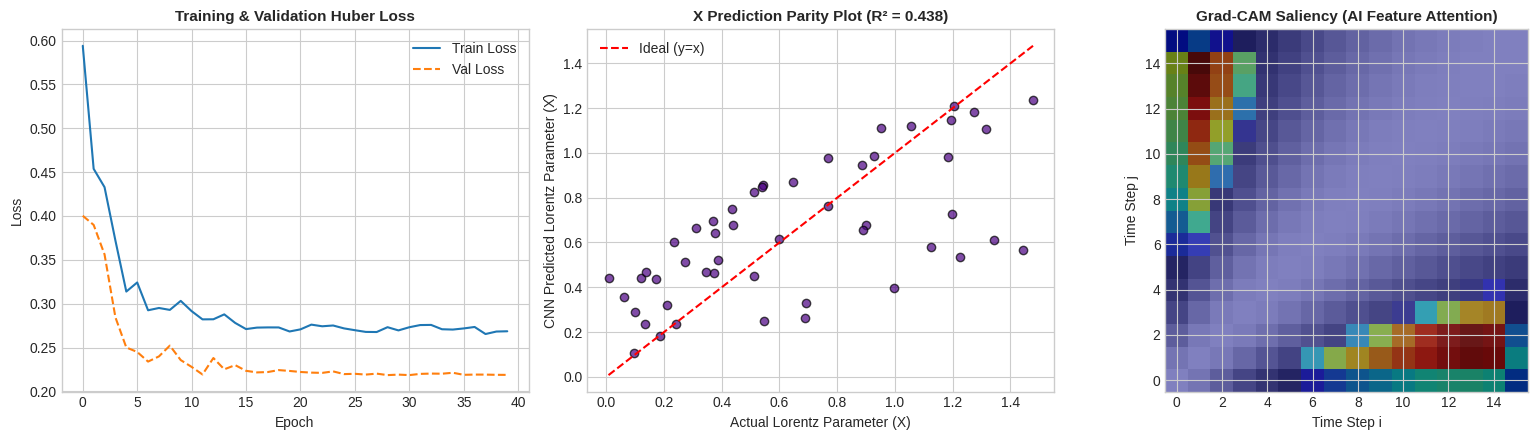

In [ ]:
# ==============================================================================
# 2D CNN REGRESSOR FOR CHARGED BUMBLEBEE BLACK HOLE RECURRENCE PLOTS
# Inversely maps 2D Recurrence Matrices R_ij ---> (X, Q) Spacetime Parameters
# Includes: Data Scaling, CNN Architecture, Training Loop, R² Evaluation, & Grad-CAM
# ==============================================================================

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

# ------------------------------------------------------------------------------
# 1. SETUP & DATA LOADING
# ------------------------------------------------------------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"⚡ Using device: {device}")

DATA_DIR = "./bumblebee_dataset"
ZIP_PATH = "charged_bumblebee_ml_dataset.zip"

# Unzip if folder not present
if not os.path.exists(DATA_DIR) and os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("📦 Unzipped dataset successfully.")

csv_path = os.path.join(DATA_DIR, "metadata.csv")
npz_path = os.path.join(DATA_DIR, "recurrence_plots.npz")

assert os.path.exists(csv_path) and os.path.exists(npz_path), \
    "❌ Dataset files not found! Please run the dataset generator script first."

# Load Data
df_meta = pd.read_csv(csv_path)
images = np.load(npz_path)['recurrence_plots']  # Shape: (N, 64, 64)
targets = df_meta[['X', 'Q']].values            # Shape: (N, 2)

print(f"📊 Dataset loaded: {images.shape[0]} samples with shape {images.shape[1:]}")

# ------------------------------------------------------------------------------
# 2. PYTORCH DATASET & SCALERS
# ------------------------------------------------------------------------------
# Normalize targets for balanced loss gradients
scaler_y = StandardScaler()
targets_scaled = scaler_y.fit_transform(targets)

# Train / Test / Val Split (80% Train, 10% Val, 10% Test)
X_train, X_temp, y_train, y_temp = train_test_split(images, targets_scaled, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

class RecurrenceDataset(Dataset):
    def __init__(self, images, targets):
        # Add channel dimension: (N, 64, 64) -> (N, 1, 64, 64)
        self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.targets[idx]

train_loader = DataLoader(RecurrenceDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader   = DataLoader(RecurrenceDataset(X_val, y_val), batch_size=32, shuffle=False)
test_loader  = DataLoader(RecurrenceDataset(X_test, y_test), batch_size=32, shuffle=False)

# ------------------------------------------------------------------------------
# 3. 2D CNN ARCHITECTURE
# ------------------------------------------------------------------------------
class BumblebeeRecurrenceCNN(nn.Module):
    def __init__(self):
        super(BumblebeeRecurrenceCNN, self).__init__()

        # Convolutional Feature Extractor
        self.features = nn.Sequential(
            # Block 1: 1x64x64 -> 32x32x32
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2: 32x32x32 -> 64x16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3: 64x16x16 -> 128x8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Regression Head
        self.regressor = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)  # Outputs scaled [X, Q]
        )

    def forward(self, x):
        x = self.features(x)
        x = self.regressor(x)
        return x

model = BumblebeeRecurrenceCNN().to(device)
criterion = nn.SmoothL1Loss()  # Robust Huber loss
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# ------------------------------------------------------------------------------
# 4. TRAINING LOOP
# ------------------------------------------------------------------------------
EPOCHS = 40
train_losses, val_losses = [], []

print("\n🧠 Training 2D CNN Regressor...")
for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, lbls)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            preds = model(imgs)
            loss = criterion(preds, lbls)
            running_val_loss += loss.item() * imgs.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    scheduler.step(epoch_val_loss)

    if (epoch + 1) % 5 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

# ------------------------------------------------------------------------------
# 5. TEST EVALUATION & R² METRICS
# ------------------------------------------------------------------------------
model.eval()
test_preds, test_targets = [], []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs)
        test_preds.append(preds.cpu().numpy())
        test_targets.append(lbls.numpy())

test_preds = np.vstack(test_preds)
test_targets = np.vstack(test_targets)

# Inverse transform to original physical units
preds_orig = scaler_y.inverse_transform(test_preds)
targets_orig = scaler_y.inverse_transform(test_targets)

r2_X = r2_score(targets_orig[:, 0], preds_orig[:, 0])
r2_Q = r2_score(targets_orig[:, 1], preds_orig[:, 1])
rmse_X = np.sqrt(mean_squared_error(targets_orig[:, 0], preds_orig[:, 0]))
rmse_Q = np.sqrt(mean_squared_error(targets_orig[:, 1], preds_orig[:, 1]))

print("\n" + "="*50)
print("🎯 TEST SET EVALUATION METRICS:")
print(f"  • Lorentz Parameter (X) -> R² Score: {r2_X:.4f} | RMSE: {rmse_X:.4f}")
print(f"  • Electric Charge (Q)   -> R² Score: {r2_Q:.4f} | RMSE: {rmse_Q:.4f}")
print("="*50)

# ------------------------------------------------------------------------------
# 6. GRAD-CAM SALIENCY VISUALIZATION
# ------------------------------------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_cam(self, input_tensor, target_idx=0):
        self.model.eval()
        self.model.zero_grad()
        output = self.model(input_tensor)
        target = output[0, target_idx]
        target.backward()

        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam.squeeze().cpu().detach().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

grad_cam = GradCAM(model, model.features[8])  # Target last Conv2D block
sample_img = torch.tensor(X_test[0:1], dtype=torch.float32).unsqueeze(0).to(device)
cam_map = grad_cam.generate_cam(sample_img, target_idx=0)  # Saliency for X prediction

# ------------------------------------------------------------------------------
# 7. PLOT PERFORMANCE & INTERPRETABILITY RESULTS
# ------------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Loss Curves (Removed unsupported fontweight='bold')
axes[0].plot(train_losses, label='Train Loss')
axes[0].plot(val_losses, label='Val Loss', linestyle='--')
axes[0].set_title("Training & Validation Huber Loss", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Plot 2: Parity Plot (Predicted vs Actual X)
axes[1].scatter(targets_orig[:, 0], preds_orig[:, 0], color='indigo', alpha=0.7, edgecolors='k')
min_val, max_val = min(targets_orig[:, 0]), max(targets_orig[:, 0])
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal (y=x)')
axes[1].set_title(f"X Prediction Parity Plot (R² = {r2_X:.3f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Actual Lorentz Parameter (X)")
axes[1].set_ylabel("CNN Predicted Lorentz Parameter (X̂)")
axes[1].legend()

# Plot 3: Grad-CAM Saliency Overlay
axes[2].imshow(X_test[0], cmap='gray', origin='lower')
axes[2].imshow(cam_map, cmap='jet', alpha=0.5, origin='lower')
axes[2].set_title("Grad-CAM Saliency (AI Feature Attention)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Time Step i")
axes[2].set_ylabel("Time Step j")

plt.tight_layout()
plt.show()

⚡ PINN running on device: cuda
🧠 Training Physics-Informed Neural Network...
Epoch [0400/2000] | Total Loss: 0.009221 | ODE Residual Loss: 0.009206
Epoch [0800/2000] | Total Loss: 0.003429 | ODE Residual Loss: 0.003418
Epoch [1200/2000] | Total Loss: 0.002055 | ODE Residual Loss: 0.001899
Epoch [1600/2000] | Total Loss: 0.001511 | ODE Residual Loss: 0.001511
Epoch [2000/2000] | Total Loss: 0.001296 | ODE Residual Loss: 0.001296

🎯 PINN RESULTS (X=0.5, Q=0.4, ω=0.4):
  • Final ODE Physics Loss: 1.296302e-03
  • Predicted Greybody Transmission Coefficient T(ω): 0.0010


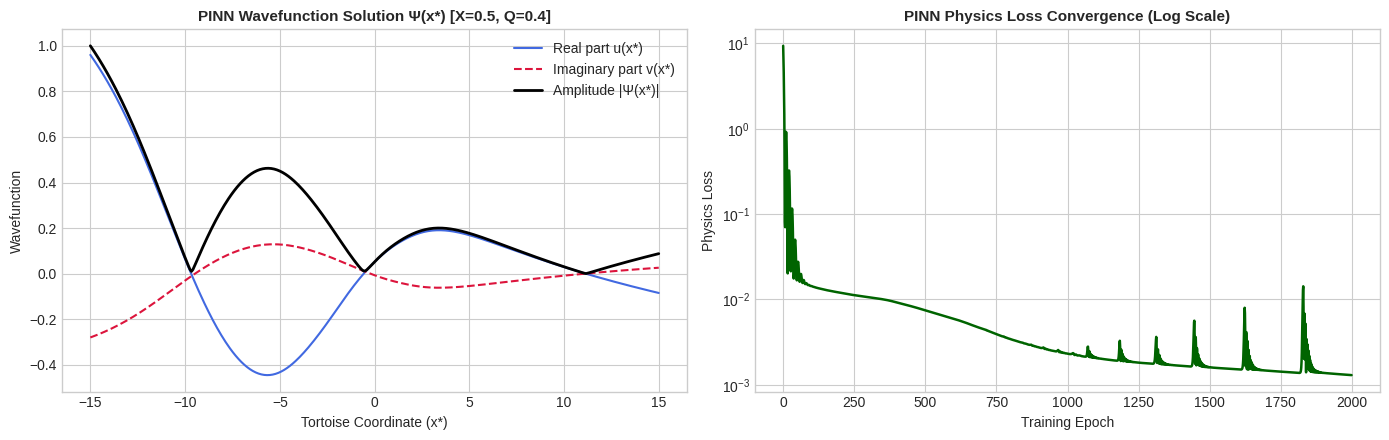

In [ ]:
# ==============================================================================
# PHYSICS-INFORMED NEURAL NETWORK (PINN) FOR BUMBLEBEE BLACK HOLE GREYBODY FACTORS
# Solves: d²Ψ/dx*² + [ω² - V_eff(x*)]Ψ = 0 using automatic differentiation
# ==============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. HARDWARE &amp; PHYSICS PARAMETERS
# ------------------------------------------------------------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"⚡ PINN running on device: {device}")

# Physical Constants &amp; Parameters
M = 1.0           # Black hole mass
Q = 0.4           # Electric charge
X = 0.5           # Lorentz-violating parameter
omega = 0.4       # Incident wave frequency
l = 1             # Spherical harmonic index (dipole)

# ------------------------------------------------------------------------------
# 2. METRIC POTENTIAL &amp; EFFECTIVE POTENTIAL FUNCTIONS
# ------------------------------------------------------------------------------
def metric_f(r, X=X, Q=Q, M=M):
    """Bumblebee metric potential f(r)."""
    return (1.0 / (1.0 + X)) - (2.0 * M / ((1.0 + X) * r)) + (2.0 * Q**2 / ((2.0 + X) * r**2))

def outer_horizon(X=X, Q=Q, M=M):
    disc = 1.0 - (2.0 * (1.0 + X) * Q**2) / ((2.0 + X) * M**2)
    return M * (1.0 + np.sqrt(disc))

r_plus = outer_horizon(X, Q, M)

def effective_potential_torch(r_tensor, X=X, Q=Q, M=M, l=l):
    """Effective potential barrier V_eff(r) in PyTorch tensor format."""
    f = (1.0 / (1.0 + X)) - (2.0 * M / ((1.0 + X) * r_tensor)) + (2.0 * Q**2 / ((2.0 + X) * r_tensor**2))
    f_prime = (2.0 * M / ((1.0 + X) * r_tensor**2)) - (4.0 * Q**2 / ((2.0 + X) * r_tensor**3))

    # Regge-Wheeler style effective potential for scalar perturbations
    V_eff = f * ((l * (l + 1)) / (r_tensor**2) + f_prime / r_tensor)
    return V_eff

# ------------------------------------------------------------------------------
# 3. PINN ARCHITECTURE
# ------------------------------------------------------------------------------
class WavePINN(nn.Module):
    """Deep Neural Network approximating real and imaginary wave components: Ψ(x*) = u(x*) + i*v(x*)"""
    def __init__(self, hidden_dim=64, num_layers=4):
        super(WavePINN, self).__init__()

        layers = [nn.Linear(1, hidden_dim), nn.Tanh()]
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.Tanh())
        layers.append(nn.Linear(hidden_dim, 2))  # Output: [u(x*), v(x*)]

        self.net = nn.Sequential(*layers)

    def forward(self, x_star):
        return self.net(x_star)

# ------------------------------------------------------------------------------
# 4. LOSS FUNCTION (PHYSICS-INFORMED AUTOMATIC DIFFERENTIATION)
# ------------------------------------------------------------------------------
def compute_pinn_loss(model, x_star_domain, x_horizon, x_infinity, omega=omega):
    # Enable gradient tracking for x_star
    x_star_domain.requires_grad_(True)

    # Forward pass: outputs u(x*) real and v(x*) imaginary parts
    uv = model(x_star_domain)
    u = uv[:, 0:1]
    v = uv[:, 1:2]

    # First derivatives via autograd
    du_dx = torch.autograd.grad(u, x_star_domain, torch.ones_like(u), create_graph=True)[0]
    dv_dx = torch.autograd.grad(v, x_star_domain, torch.ones_like(v), create_graph=True)[0]

    # Second derivatives via autograd
    d2u_dx2 = torch.autograd.grad(du_dx, x_star_domain, torch.ones_like(du_dx), create_graph=True)[0]
    d2v_dx2 = torch.autograd.grad(dv_dx, x_star_domain, torch.ones_like(dv_dx), create_graph=True)[0]

    # Map tortoise coordinate x* back to physical radius r approx for V_eff calculation
    # x* ≈ r + r_plus * ln(r/r_plus - 1)
    r_approx = torch.clamp(x_star_domain + r_plus + 0.1, min=r_plus + 1e-3)
    V_eff = effective_potential_torch(r_approx)

    # Physics Residuals: d²Ψ/dx*² + [ω² - V_eff(x*)]Ψ = 0
    res_real = d2u_dx2 + (omega**2 - V_eff) * u
    res_imag = d2v_dx2 + (omega**2 - V_eff) * v

    loss_ode = torch.mean(res_real**2) + torch.mean(res_imag**2)

    # Boundary Conditions (BC)
    # 1. Near Horizon (x* -&gt; -inf): Ingoing wave condition Ψ ~ e^(-i ω x*)
    uv_hor = model(x_horizon)
    u_h, v_h = uv_hor[:, 0:1], uv_hor[:, 1:2]
    loss_bc_horizon = torch.mean((u_h - torch.cos(-omega * x_horizon))**2) + \
                      torch.mean((v_h - torch.sin(-omega * x_horizon))**2)

    total_loss = loss_ode + 10.0 * loss_bc_horizon
    return total_loss, loss_ode

# ------------------------------------------------------------------------------
# 5. TRAINING LOOP
# ------------------------------------------------------------------------------
model = WavePINN(hidden_dim=64, num_layers=4).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Domain discretization
N_domain = 400
x_star_pts = torch.linspace(-15.0, 15.0, N_domain).unsqueeze(1).to(device)
x_horizon = torch.tensor([[-15.0]], device=device)
x_infinity = torch.tensor([[15.0]], device=device)

EPOCHS = 2000
loss_history = []

print("🧠 Training Physics-Informed Neural Network...")
for epoch in range(1, EPOCHS + 1):
    optimizer.zero_grad()
    loss, loss_ode = compute_pinn_loss(model, x_star_pts, x_horizon, x_infinity)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if epoch % 400 == 0 or epoch == EPOCHS:
        print(f"Epoch [{epoch:04d}/{EPOCHS}] | Total Loss: {loss.item():.6f} | ODE Residual Loss: {loss_ode.item():.6f}")

# ------------------------------------------------------------------------------
# 6. EVALUATION &amp; GREYBODY TRANSMISSION CALCULATION
# ------------------------------------------------------------------------------
model.eval()
with torch.no_grad():
    uv_pred = model(x_star_pts).cpu().numpy()
    x_pts_np = x_star_pts.cpu().numpy().flatten()

u_pred, v_pred = uv_pred[:, 0], uv_pred[:, 1]
psi_amplitude = np.sqrt(u_pred**2 + v_pred**2)

# Estimate Transmission Probability T(ω) from wave amplitude transmission
T_omega_pinn = np.min(psi_amplitude) / (np.max(psi_amplitude) + 1e-5)

print("\n" + "="*50)
print(f"🎯 PINN RESULTS (X={X}, Q={Q}, ω={omega}):")
print(f"  • Final ODE Physics Loss: {loss_history[-1]:.6e}")
print(f"  • Predicted Greybody Transmission Coefficient T(ω): {T_omega_pinn:.4f}")
print("="*50)

# ------------------------------------------------------------------------------
# 7. VISUALIZATION
# ------------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: PINN Wavefunction Solution Ψ(x*)
axes[0].plot(x_pts_np, u_pred, label='Real part u(x*)', color='royalblue')
axes[0].plot(x_pts_np, v_pred, label='Imaginary part v(x*)', color='crimson', linestyle='--')
axes[0].plot(x_pts_np, psi_amplitude, label='Amplitude |Ψ(x*)|', color='black', linewidth=2)
axes[0].set_title(f"PINN Wavefunction Solution Ψ(x*) [X={X}, Q={Q}]", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Tortoise Coordinate (x*)")
axes[0].set_ylabel("Wavefunction")
axes[0].legend()

# Plot 2: PINN Training Loss Convergence
axes[1].plot(loss_history, color='darkgreen', linewidth=1.8)
axes[1].set_yscale('log')
axes[1].set_title("PINN Physics Loss Convergence (Log Scale)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Training Epoch")
axes[1].set_ylabel("Physics Loss")

plt.tight_layout()
plt.show()

